<div align="center">
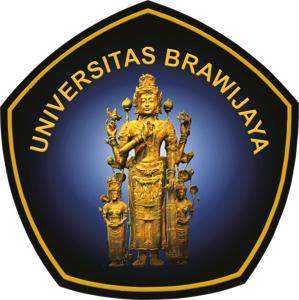

# PENGENALAN ISYARAT ANGKA BISINDO

## HITUNGIN

**MediaPipe · MLP · ONNX**

Notebook eksperimen pembelajaran mesin · LOGICODIX 2026  
Universitas Brawijaya · Malang · 2026

**Penyusun: Tim HITUNGIN**

</div>

---

**Alur CRISP-DM:** Pemahaman Bisnis → Pemahaman Data → Persiapan Data → Pemodelan → Evaluasi → Deployment.

**Cara menjalankan:** pilih runtime GPU T4 di Google Colab, kemudian jalankan sel secara berurutan.
Profil `poc` adalah eksperimen terbatas yang benar-benar melatih dan mengevaluasi model;
ubah `HITUNGIN_PROFILE=full` sebelum sel konfigurasi untuk eksperimen lebih panjang.
Hasil pengenalan selalu dikonfirmasi pengguna sebelum dinilai dengan aturan matematika.
Logo merupakan identitas cover, bukan tanda pengesahan universitas.


## Petunjuk reproduksi

Notebook ini mandiri: mengunduh data publik bila belum tersedia, menetapkan seed,
mencatat versi paket, dan menyimpan artefak di `artifacts/`. Direktori runtime Colab
bersifat sementara. Unduh ZIP artefak di akhir sebelum menutup sesi.
Nilai metrik tidak diisi manual; semuanya dihitung oleh sel evaluasi.


In [ ]:
# @title Instalasi dependensi
%pip -q install requests pandas numpy matplotlib scikit-learn onnx==1.19.1 onnxruntime==1.23.2


In [ ]:
# @title Konfigurasi eksperimen dan utilitas

import os, sys, json, random, time, copy, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path('/content/hitungin') if Path('/content').exists() else Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
ROOT.mkdir(parents=True, exist_ok=True)
PROFILE = os.environ.get('HITUNGIN_PROFILE', 'poc')
assert PROFILE in {'poc', 'full'}
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
print({'profil': PROFILE, 'perangkat': str(DEVICE), 'python': platform.python_version(),
       'torch': torch.__version__, 'root': str(ROOT)})
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str) + '\n')

def save_environment(folder):
    import importlib.metadata as metadata
    names = ['torch', 'numpy', 'pandas', 'scikit-learn', 'onnx', 'onnxruntime',
             'transformers', 'accelerate', 'jiwer', 'soundfile']
    versions = {}
    for name in names:
        try: versions[name] = metadata.version(name)
        except metadata.PackageNotFoundError: pass
    save_json(folder / 'environment.json', versions)

def index_artifacts(folder):
    records = []
    for path in sorted(folder.rglob('*')):
        if path.is_file() and path.name != 'manifest.json':
            sha = hashlib.sha256()
            with path.open('rb') as handle:
                for block in iter(lambda: handle.read(1024*1024), b''): sha.update(block)
            records.append({'file': str(path.relative_to(folder)), 'bytes': path.stat().st_size,
                            'sha256': sha.hexdigest()})
    save_json(folder / 'manifest.json', records)
    return pd.DataFrame(records)


{'profil': 'poc', 'perangkat': 'cuda', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'root': '/content/hitungin'}
GPU: Tesla T4


In [ ]:
# @title Pengunduh sumber publik (dapat dijalankan ulang)
import concurrent.futures
import hashlib
import io
import json
import subprocess
import sys
import time
import zipfile
from pathlib import Path
import requests
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
def download(url, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        partial = path.with_suffix(path.suffix + ".part")
        for attempt in range(3):
            try:
                offset = partial.stat().st_size if partial.exists() else 0
                headers = {"Range": f"bytes={offset}-"} if offset else {}
                with requests.get(url, headers=headers, stream=True, timeout=(30, 120)) as response:
                    response.raise_for_status()
                    append = offset and response.status_code == 206
                    if append:
                        assert response.headers.get("Content-Range", "").startswith(f"bytes {offset}-"), "Invalid resume response"
                    with partial.open("ab" if append else "wb") as output:
                        for chunk in response.iter_content(1024 * 1024):
                            output.write(chunk)
                partial.replace(path)
                break
            except requests.RequestException:
                if attempt == 2:
                    raise
                time.sleep(2)
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return {"url": url, "path": str(path.relative_to(ROOT)),
            "bytes": path.stat().st_size, "sha256": digest.hexdigest()}

def extract_zip(archive, destination, select=lambda name: True):
    destination.mkdir(parents=True, exist_ok=True)
    base = destination.resolve()
    with zipfile.ZipFile(archive) as source:
        for member in source.infolist():
            if not select(member.filename):
                continue
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(base):
                raise ValueError(f"Unsafe archive path: {member.filename}")
            source.extract(member, destination)

def bisindo():
    ref = "suryaadji/bisindo-alphabet-mediapipe-hand-landmarks"
    folder = DATA / "raw/bisindo"
    folder.mkdir(parents=True, exist_ok=True)
    response = requests.get(f"https://www.kaggle.com/api/v1/datasets/view/{ref}", timeout=30)
    response.raise_for_status()
    metadata = response.json()
    (folder / "source_metadata.json").write_text(json.dumps(metadata, indent=2))
    version = metadata["currentVersionNumber"]
    item = download(f"https://www.kaggle.com/api/v1/datasets/download/{ref}?datasetVersionNumber={version}",
                    DATA / f".downloads/bisindo-v{version}.zip")
    extract_zip(ROOT / item["path"], folder)
    return {"dataset": "bisindo", "version": version, "downloads": [item]}


# 1. Pemahaman Bisnis

**Masalah:** siswa menjawab latihan matematika melalui isyarat angka. Sistem
menerjemahkan gerakan menjadi kandidat digit 0–9, bukan menilai kemampuan siswa.
Kamera dan inferensi tetap berada di perangkat saat aplikasi browser digunakan.

**Batas PoC:** isyarat statis, maksimum dua tangan, satu digit per pengenalan.
Dataset berlabel BISINDO dipakai sesuai publikasi pembuatnya; kesesuaian dialek
dan kebiasaan pengguna belum divalidasi. Bilangan seperti 35 disusun dari 3 dan 5
dengan tombol tambah digit, kemudian dikonfirmasi sebagai satu jawaban.

| Aspek | Keputusan eksperimen |
|---|---|
| Baseline | Logistic regression |
| Model utama | MLP kecil pada landmark dua tangan |
| Metrik utama | Akurasi, macro-F1, coverage, akurasi kandidat yang diterima |
| Ambang penolakan | Dipilih dari data kalibrasi, bukan data evaluasi akhir |
| Sasaran awal | Akurasi kandidat diterima ≥95%, coverage ≥85%; bukan jaminan |
| Risiko | Data sedikit, tidak ada identitas pengisyarat, urutan tangan belum terdokumentasi |


In [ ]:
# @title Parameter dan direktori keluaran
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
ART = ROOT / 'artifacts/bisindo'
ART.mkdir(parents=True, exist_ok=True)
CONFIG = {'seed': SEED, 'epochs': 180 if PROFILE == 'full' else 100,
          'batch_size': 64, 'lr': 0.001, 'patience': 20, 'classes': list(range(10)),
          'target_accepted_accuracy': 0.95, 'target_coverage': 0.85}
display(pd.Series(CONFIG, name='konfigurasi'))


,konfigurasi
seed,42
epochs,100
batch_size,64
lr,0.001
patience,20
classes,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
target_accepted_accuracy,0.95
target_coverage,0.85


# 2. Pemahaman Data

Sumber: [BISINDO MediaPipe Hand Landmarks, versi 3](https://www.kaggle.com/datasets/suryaadji/bisindo-alphabet-mediapipe-hand-landmarks).
Lisensi yang tercantum: CC BY 4.0; atribusi kepada Adjie / `suryaadji` disimpan.
Angka statis memiliki 126 fitur: 2 tangan × 21 titik × 3 koordinat. Label 10
tersedia, tetapi dikeluarkan karena tugas ini mengenali digit 0–9.
Data dinamis 11–20 dan alfabet bukan target training notebook ini.


,h0_lm0_x,h0_lm0_y,h0_lm0_z,h0_lm1_x,h0_lm1_y,h0_lm1_z,h0_lm2_x,h0_lm2_y,h0_lm2_z,h0_lm3_x,...,h1_lm18_x,h1_lm18_y,h1_lm18_z,h1_lm19_x,h1_lm19_y,h1_lm19_z,h1_lm20_x,h1_lm20_y,h1_lm20_z,label
0,0.536686,0.823513,-2.191494e-07,0.486782,0.795391,-0.010914,0.449164,0.739642,-0.021930,0.420964,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.516596,0.894064,-2.742573e-07,0.466531,0.831246,-0.008813,0.439270,0.753916,-0.016376,0.425411,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,0.457810,0.789254,-2.216645e-07,0.431309,0.709280,-0.005814,0.427412,0.626275,-0.011256,0.428753,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0.570342,0.684840,-9.193751e-08,0.532612,0.697545,-0.012833,0.497188,0.685697,-0.025739,0.471619,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,0.559015,0.732250,1.003540e-08,0.519687,0.743455,-0.014467,0.484386,0.722151,-0.028167,0.455064,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


,train_publik,validasi_publik
label,,
0,45,12
1,44,11
2,44,11
3,44,11
4,44,11
5,44,11
6,56,15
7,58,15
8,60,16


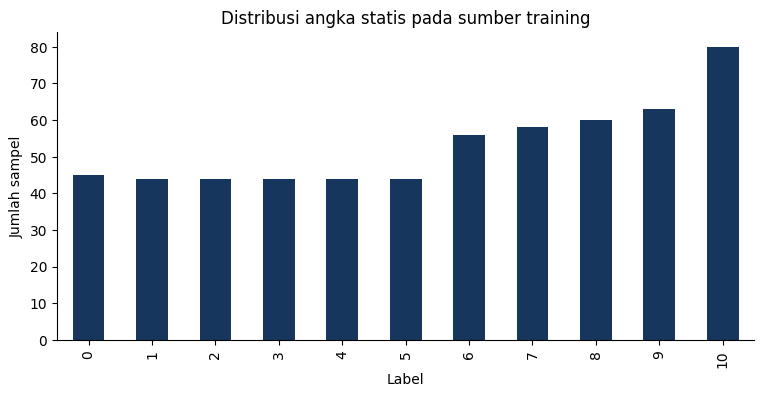

In [ ]:
# @title Muat data, simpan metadata sumber, dan periksa skema
if not (DATA / 'raw/bisindo/Numbers/Static/landmarks_numbers_train.csv').exists():
    print(bisindo())
folder = DATA / 'raw/bisindo/Numbers/Static'
train_raw = pd.read_csv(folder / 'landmarks_numbers_train.csv')
test_raw = pd.read_csv(folder / 'landmarks_numbers_val.csv')
features = [f'h{h}_lm{j}_{axis}' for h in range(2) for j in range(21) for axis in 'xyz']
assert list(train_raw.columns) == features + ['label']
assert list(test_raw.columns) == features + ['label']
assert np.isfinite(train_raw.to_numpy()).all() and np.isfinite(test_raw.to_numpy()).all()
display(train_raw.head())
display(pd.DataFrame({'train_publik': train_raw.label.value_counts(),
                      'validasi_publik': test_raw.label.value_counts()}).sort_index())
train_raw.label.value_counts().sort_index().plot.bar(color='#17365d', title='Distribusi angka statis pada sumber training')
plt.xlabel('Label'); plt.ylabel('Jumlah sampel'); plt.show()


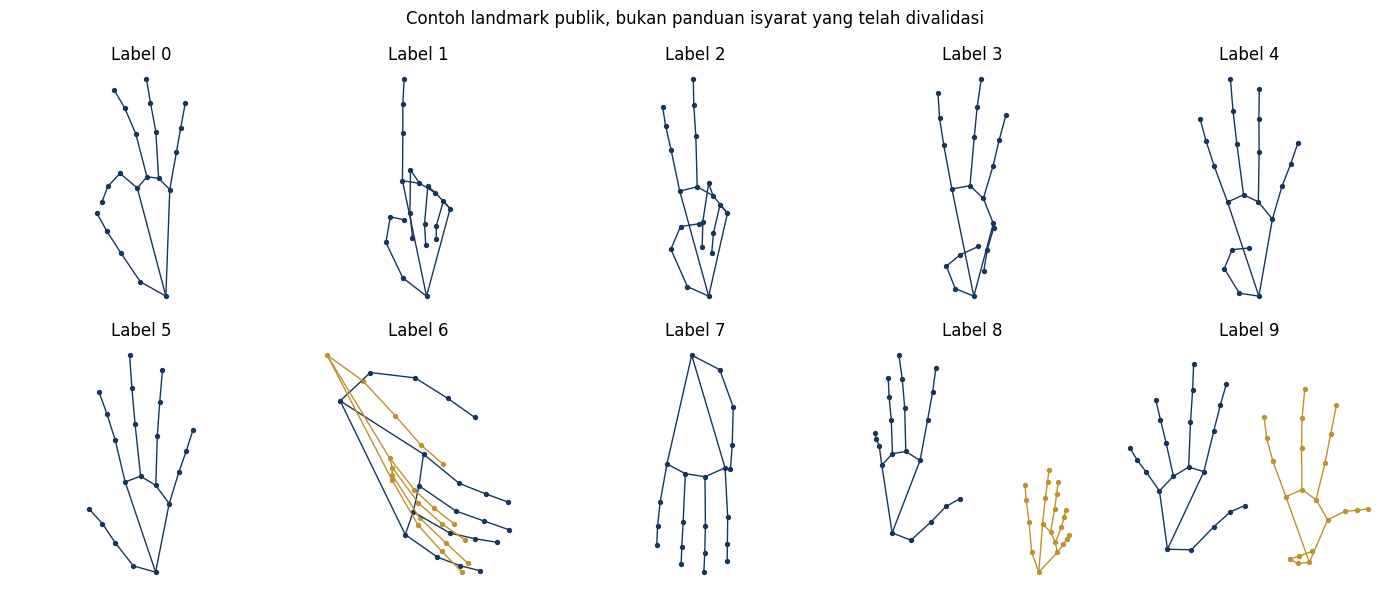

In [ ]:
# @title Visualisasikan landmark contoh agar kualitas data dapat diperiksa
EDGES = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
         (9,13),(13,14),(14,15),(15,16),(13,17),(0,17),(17,18),(18,19),(19,20)]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for digit, ax in enumerate(axes.flat):
    points = train_raw.loc[train_raw.label == digit, features].iloc[0].to_numpy().reshape(2,21,3)
    for hand, color in zip(points, ['#17365d', '#bf922d']):
        if np.abs(hand).sum() == 0: continue
        ax.scatter(hand[:,0], -hand[:,1], s=8, color=color)
        for a,b in EDGES: ax.plot(hand[[a,b],0], -hand[[a,b],1], color=color, linewidth=1)
    ax.set_title(f'Label {digit}'); ax.axis('equal'); ax.axis('off')
plt.suptitle('Contoh landmark publik, bukan panduan isyarat yang telah divalidasi'); plt.tight_layout(); plt.show()


# 3. Persiapan Data

Kita mempertahankan validasi publik sebagai **evaluasi akhir internal**.
Sebagian training publik dipisahkan untuk kalibrasi dan pemilihan checkpoint.
Duplikasi fitur lintas partisi dibuang dari partisi evaluasi. Karena tidak ada
ID pengisyarat, split ini **tidak membuktikan generalisasi ke orang baru**.

Normalisasi memakai titik pergelangan tangan pertama yang tersedia sebagai
jangkar global dan ukuran telapak sebagai skala. Hubungan posisi kedua tangan
dipertahankan. Dua penanda keberadaan tangan ditambahkan, menghasilkan 128 fitur.
Tidak ada rotasi atau pencerminan otomatis yang bisa mengubah makna isyarat.


In [ ]:
# @title Audit duplikasi, filter kelas, dan buat partisi
train_df = train_raw[train_raw.label.between(0,9)].drop_duplicates(features).copy()
test_df = test_raw[test_raw.label.between(0,9)].drop_duplicates(features).copy()
train_hash = set(pd.util.hash_pandas_object(train_df[features], index=False))
overlap = pd.util.hash_pandas_object(test_df[features], index=False).isin(train_hash)
print('Duplikasi fitur lintas sumber:', int(overlap.sum()))
test_df = test_df.loc[~overlap].copy()
fit_df, cal_df = train_test_split(train_df, test_size=0.2, stratify=train_df.label, random_state=SEED)
split_info = {'training': len(fit_df), 'kalibrasi': len(cal_df), 'evaluasi_akhir': len(test_df),
              'signer_independent': False, 'feature_overlap_removed': int(overlap.sum())}
display(pd.Series(split_info))
save_json(ART / 'split.json', split_info)


Duplikasi fitur lintas sumber: 0


,0
training,401
kalibrasi,101
evaluasi_akhir,130
signer_independent,False
feature_overlap_removed,0


In [ ]:
# @title Normalisasi yang juga harus diterapkan di browser
def normalize_landmarks(array):
    points = np.asarray(array, dtype=np.float32).reshape(-1, 2, 21, 3).copy()
    present = np.any(np.abs(points) > 1e-8, axis=(2,3))
    anchor_index = np.where(present[:,0], 0, 1)
    anchor = points[np.arange(len(points)), anchor_index, 0].copy()
    palm = np.linalg.norm(points[:,:,9] - points[:,:,0], axis=-1)
    scale = np.maximum((palm * present).sum(axis=1) / np.maximum(present.sum(axis=1), 1), 1e-5)
    points = (points - anchor[:,None,None,:]) / scale[:,None,None,None]
    points *= present[:,:,None,None]
    return np.concatenate([points.reshape(-1,126), present.astype(np.float32)], axis=1).astype(np.float32)

X_fit = normalize_landmarks(fit_df[features].to_numpy()); y_fit = fit_df.label.to_numpy().astype('int64')
X_cal = normalize_landmarks(cal_df[features].to_numpy()); y_cal = cal_df.label.to_numpy().astype('int64')
X_test = normalize_landmarks(test_df[features].to_numpy()); y_test = test_df.label.to_numpy().astype('int64')
assert X_fit.shape[1] == 128 and np.isfinite(X_fit).all()


# 4. Pemodelan

Baseline linear membantu menilai apakah MLP memberi manfaat pada data kecil ini.
Model utama: `128 → 128 → 64 → 10`, ReLU dan dropout. Loss cross-entropy berbobot
menyeimbangkan kelas. Early stopping mengikuti loss kalibrasi; evaluasi akhir
belum dipakai. Seed tetap membuat perbandingan lebih mudah direproduksi.


In [ ]:
# @title Baseline dan definisi MLP
baseline = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_fit, y_fit)
print('Baseline pada kalibrasi:', accuracy_score(y_cal, baseline.predict(X_cal)))
class SignMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(128,128), nn.ReLU(), nn.Dropout(0.15),
                                 nn.Linear(128,64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64,10))
    def forward(self, x): return self.net(x)

model = SignMLP().to(DEVICE)
weights = len(y_fit) / (10 * np.bincount(y_fit, minlength=10))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=1e-4)
loader = DataLoader(TensorDataset(torch.from_numpy(X_fit), torch.from_numpy(y_fit)),
                    batch_size=CONFIG['batch_size'], shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
print('Parameter:', sum(p.numel() for p in model.parameters()))


Baseline pada kalibrasi: 0.9603960396039604
Parameter: 25418


{'epoch': 10, 'train_loss': 1.270023413429831, 'val_loss': 1.1856743097305298, 'val_accuracy': np.float64(0.8118811881188119)}
{'epoch': 20, 'train_loss': 0.5941567838637906, 'val_loss': 0.5067146420478821, 'val_accuracy': np.float64(0.9504950495049505)}


{'epoch': 30, 'train_loss': 0.3010461255350612, 'val_loss': 0.27560803294181824, 'val_accuracy': np.float64(0.9504950495049505)}
{'epoch': 40, 'train_loss': 0.1667603861512686, 'val_loss': 0.16801103949546814, 'val_accuracy': np.float64(0.9801980198019802)}


{'epoch': 50, 'train_loss': 0.10105882811724694, 'val_loss': 0.12043916434049606, 'val_accuracy': np.float64(0.9900990099009901)}
{'epoch': 60, 'train_loss': 0.0632596955613751, 'val_loss': 0.0972261056303978, 'val_accuracy': np.float64(0.9900990099009901)}


{'epoch': 70, 'train_loss': 0.053376239624589754, 'val_loss': 0.08967093378305435, 'val_accuracy': np.float64(0.9801980198019802)}
{'epoch': 80, 'train_loss': 0.03792324146613516, 'val_loss': 0.09270843118429184, 'val_accuracy': np.float64(0.9900990099009901)}


{'epoch': 90, 'train_loss': 0.02976119325048014, 'val_loss': 0.0859043300151825, 'val_accuracy': np.float64(0.9801980198019802)}
{'epoch': 100, 'train_loss': 0.028465720657677277, 'val_loss': 0.08796589821577072, 'val_accuracy': np.float64(0.9801980198019802)}


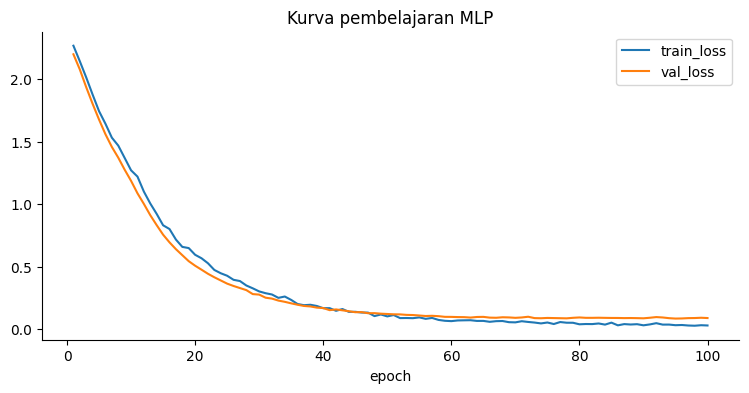

In [ ]:
# @title Training, early stopping, dan checkpoint terbaik
history, best_loss, stale = [], float('inf'), 0
started = time.perf_counter()
for epoch in range(CONFIG['epochs']):
    model.train(); total_loss = 0
    for x,y in loader:
        x,y = x.to(DEVICE),y.to(DEVICE)
        optimizer.zero_grad(); loss = criterion(model(x),y); loss.backward(); optimizer.step()
        total_loss += loss.item()*len(x)
    model.eval()
    with torch.no_grad():
        val_logits = model(torch.from_numpy(X_cal).to(DEVICE))
        val_loss = criterion(val_logits, torch.from_numpy(y_cal).to(DEVICE)).item()
        val_acc = (val_logits.argmax(1).cpu().numpy() == y_cal).mean()
    history.append({'epoch': epoch+1, 'train_loss': total_loss/len(X_fit), 'val_loss': val_loss, 'val_accuracy': val_acc})
    if val_loss < best_loss:
        best_loss, stale = val_loss, 0
        torch.save(model.state_dict(), ART / 'best_training.pt')
    else: stale += 1
    if (epoch+1)%10 == 0: print(history[-1])
    if stale >= CONFIG['patience']: break
model.load_state_dict(torch.load(ART / 'best_training.pt', map_location=DEVICE, weights_only=True))
training_seconds = time.perf_counter()-started
history_df = pd.DataFrame(history); history_df.to_csv(ART/'history.csv', index=False)
history_df.plot(x='epoch', y=['train_loss','val_loss']); plt.title('Kurva pembelajaran MLP'); plt.show()


In [ ]:
# @title Pilih ambang confidence dari partisi kalibrasi
model.eval()
with torch.no_grad(): cal_prob = model(torch.from_numpy(X_cal).to(DEVICE)).softmax(1).cpu().numpy()
sweep = []
for threshold in np.linspace(0.6,0.99,40):
    keep = cal_prob.max(1) >= threshold
    sweep.append({'threshold': float(threshold), 'coverage': float(keep.mean()),
                  'accepted_accuracy': float((cal_prob.argmax(1)[keep]==y_cal[keep]).mean()) if keep.any() else None})
sweep_df = pd.DataFrame(sweep)
eligible = sweep_df[(sweep_df.accepted_accuracy >= CONFIG['target_accepted_accuracy']) &
                    (sweep_df.coverage >= CONFIG['target_coverage'])]
THRESHOLD = float(eligible.iloc[0].threshold) if len(eligible) else 0.9
print('Ambang:', THRESHOLD, '| Sasaran kalibrasi tercapai:', bool(len(eligible)))
sweep_df.to_csv(ART/'calibration.csv', index=False)
display(sweep_df.iloc[::10])


Ambang: 0.6 | Sasaran kalibrasi tercapai: True


,threshold,coverage,accepted_accuracy
0,0.6,0.980198,1.0
10,0.7,0.980198,1.0
20,0.8,0.970297,1.0
30,0.9,0.950495,1.0


# 5. Evaluasi

Semua angka di bawah berasal dari split evaluasi akhir, yang tidak digunakan
untuk memilih model atau ambang. Laporkan coverage bersama akurasi kandidat
diterima agar penolakan tidak menyembunyikan kesalahan. Confidence softmax bukan
probabilitas kebenaran terkalibrasi. Dataset ini tidak menyediakan kelas negatif
yang representatif, sehingga false-accept rate dunia nyata belum dapat diukur.


,0
accuracy,0.976923
macro_f1,0.975521
coverage,1.0
rejection_rate,0.0
accepted_accuracy,0.976923
baseline_accuracy,0.984615
training_seconds,1.731678
test_size,130
unseen_signer_evaluation,False
negative_input_evaluation,False


              precision    recall  f1-score   support

           0      1.000     0.917     0.957        12
           1      0.917     1.000     0.957        11
           2      1.000     0.909     0.952        11
           3      0.917     1.000     0.957        11
           4      1.000     1.000     1.000        11
           5      1.000     1.000     1.000        11
           6      1.000     0.933     0.966        15
           7      0.938     1.000     0.968        15
           8      1.000     1.000     1.000        16
           9      1.000     1.000     1.000        17

    accuracy                          0.977       130
   macro avg      0.977     0.976     0.976       130
weighted avg      0.979     0.977     0.977       130



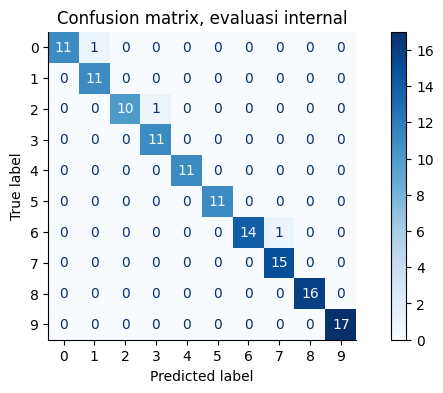

,aktual,prediksi,confidence,diterima
11,0,1,0.818272,True
30,2,3,0.744594,True
81,6,7,0.998664,True


In [ ]:
# @title Laporan klasifikasi, confusion matrix, dan analisis kesalahan
with torch.no_grad(): probs = model(torch.from_numpy(X_test).to(DEVICE)).softmax(1).cpu().numpy()
pred = probs.argmax(1); keep = probs.max(1) >= THRESHOLD
metrics = {'accuracy': accuracy_score(y_test,pred), 'macro_f1': f1_score(y_test,pred,average='macro'),
           'coverage': float(keep.mean()), 'rejection_rate': float(1-keep.mean()),
           'accepted_accuracy': float((pred[keep]==y_test[keep]).mean()) if keep.any() else None,
           'baseline_accuracy': accuracy_score(y_test,baseline.predict(X_test)),
           'training_seconds': training_seconds, 'test_size': len(y_test),
           'unseen_signer_evaluation': False, 'negative_input_evaluation': False}
display(pd.Series(metrics)); print(classification_report(y_test,pred,digits=3,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=range(10),cmap='Blues')
plt.title('Confusion matrix, evaluasi internal'); plt.show()
errors = pd.DataFrame({'aktual':y_test,'prediksi':pred,'confidence':probs.max(1),'diterima':keep})
display(errors[errors.aktual != errors.prediksi].head(15))
errors.to_csv(ART/'predictions.csv',index=False); save_json(ART/'metrics.json',metrics)


# 6. Deployment dan Penyimpanan Model

Ekspor ONNX hanya memuat classifier. Browser tetap membutuhkan MediaPipe Hand
Landmarker dan fungsi normalisasi identik. Kontrak `h0`/`h1` pada dataset belum
menjelaskan pengurutan tangan secara rinci; uji dengan kamera wajib dilakukan
sebelum menyatakan pipeline cocok. Jangan mengurutkan ulang tangan sembarangan.

Aplikasi memakai state machine: input valid → kandidat stabil → tambah digit →
konfirmasi bilangan → penilaian aturan. Tangan hilang harus mengosongkan riwayat
smoothing. Input kosong dan confidence rendah menghasilkan `uncertain`.


In [ ]:
# @title Simpan model final, spesifikasi preprocessing, dan ONNX
import onnx, onnxruntime as ort
model = model.cpu().eval()
torch.save({'state_dict': model.state_dict(), 'config': CONFIG}, ART/'sign_mlp.pt')
torch.onnx.export(model, torch.zeros(1,128), str(ART/'sign_mlp.onnx'),
                  input_names=['landmarks'], output_names=['logits'],
                  dynamic_axes={'landmarks':{0:'batch'},'logits':{0:'batch'}}, opset_version=17, dynamo=False)
onnx.checker.check_model(onnx.load(ART/'sign_mlp.onnx'))
spec = {'features': features, 'input_size':128, 'labels':list(range(10)), 'threshold':THRESHOLD,
        'normalization':'global wrist anchor; mean visible wrist-to-middle-MCP distance; append hand presence',
        'source':'suryaadji/bisindo-alphabet-mediapipe-hand-landmarks v3', 'license':'CC BY 4.0',
        'hand_order_verified_in_browser':False}
save_json(ART/'preprocessing.json',spec); save_json(ART/'config.json',CONFIG)
import inspect
(ART/'preprocessing.py').write_text('import numpy as np\n\n'+inspect.getsource(normalize_landmarks))


/tmp/ipykernel_680/662708160.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.zeros(1,128), str(ART/'sign_mlp.onnx'),


680

In [ ]:
# @title Uji muat ulang dan kesetaraan ONNX, bukan benchmark browser
session = ort.InferenceSession(str(ART/'sign_mlp.onnx'), providers=['CPUExecutionProvider'])
sample = X_test[:16]
with torch.no_grad(): reference = model(torch.from_numpy(sample)).numpy()
actual = session.run(None, {'landmarks':sample})[0]
np.testing.assert_allclose(actual, reference, rtol=1e-4, atol=1e-5)
reloaded = SignMLP(); reloaded.load_state_dict(torch.load(ART/'sign_mlp.pt',weights_only=True)['state_dict'])
with torch.no_grad(): np.testing.assert_allclose(reloaded.eval()(torch.from_numpy(sample)).numpy(),reference)
for _ in range(5): session.run(None,{'landmarks':sample[:1]})
timings=[]
for _ in range(100):
    tick=time.perf_counter(); session.run(None,{'landmarks':sample[:1]}); timings.append((time.perf_counter()-tick)*1000)
print('Parity lulus. Latensi CPU ONNX p50/p95 (ms):',np.percentile(timings,[50,95]))
save_json(ART/'export_check.json',{'max_abs_error':float(np.abs(actual-reference).max()),
          'cpu_onnx_p50_p95_ms':np.percentile(timings,[50,95]).tolist(), 'browser_benchmarked':False})


Parity lulus. Latensi CPU ONNX p50/p95 (ms): [0.016704  0.0349437]


## Kesimpulan dan tindak lanjut

Gunakan hasil evaluasi di atas untuk memutuskan apakah model siap sebagai demo.
Generalisasi ke pengisyarat baru, gesture negatif, dialek BISINDO, dan performa
MediaPipe di browser belum dibuktikan oleh notebook ini. Model yang berhasil
diekspor belum otomatis memenuhi syarat penggunaan nyata.

**Referensi:** [dataset dan atribusi](https://www.kaggle.com/datasets/suryaadji/bisindo-alphabet-mediapipe-hand-landmarks),
[MediaPipe Hand Landmarker](https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker/web_js),
[ONNX Runtime Web](https://onnxruntime.ai/docs/tutorials/web/).


In [ ]:
# @title Paket akhir untuk diunduh
import shutil
save_environment(ART)
display(index_artifacts(ART))
archive = shutil.make_archive(str(ART.parent/'bisindo'), 'zip', ART)
print('Model, metadata, dan laporan:', archive)
from IPython.display import FileLink
display(FileLink(archive))
# Di Colab, jalankan files.download(archive) bila ingin memulai unduhan browser.


,file,bytes,sha256
0,best_training.pt,104861,83242919f1b838a7f217cbfbd2a36a1b89e8d2d599513b...
1,calibration.csv,1280,d3c6f49bf8a077a757a99c5cfb91cc40d679fc2cfaa57f...
2,config.json,239,ec92fea4024a8353d1e4bcd9506b9d3f3d4414c3f0301c...
3,environment.json,244,ea9e3781e878b59bdae77e463753e83aa49175d9e1f55e...
4,export_check.json,141,cc182469aae9361dde84aa935068232b238cd9f62080ae...
5,history.csv,6156,bbcdf7e15c7b42cc49f24eed8ae99cda02b2b0bbe88d20...
6,metrics.json,338,3392bfff2e2c6fca70a12cd215b9d3a68fb6ade45e6081...
7,predictions.csv,2544,752f41104b66e092104eaea8d5e785c374433e92b1139d...
8,preprocessing.json,2480,4c945d6897d45cfaa119be664a0f8b634ca3d087517984...
9,preprocessing.py,680,8d522349a84e39f70a4b62bcda90d1bd604587c94abdc7...


Model, metadata, dan laporan: /content/hitungin/artifacts/bisindo.zip


/content/hitungin/artifacts/bisindo.zip